<a href="https://colab.research.google.com/github/Solomonskywalker/customer-intelligence-platform/blob/main/Customer_Intelligence_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os



print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)

print("seaborne version:", sns.__version__)
print("Customer intlligence")
print("Environment successfully initialized!")

Mounted at /content/drive
numpy version: 2.4.6
pandas version: 2.2.3
seaborne version: 0.13.2
Customer intlligence
Environment successfully initialized!


# Data Collection and Loading

In [ ]:
# Load the dataset from google drive
project_path = '/content/drive/MyDrive/Customer_Intelligence_Project'

df = pd.read_csv(
    project_path + '/Reviews.csv'
)

print("Dataset laded successfully")
print("Dataset shape:", df.shape)

Dataset laded successfully
Dataset shape: (20000, 14)


In [ ]:
# Understand the dataset
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (20000, 14)

Column names:
['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text', 'Review_Length', 'Review_Date', 'Review_Year', 'Review_Month']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Id                      20000 non-null  int64 
 1   ProductId               20000 non-null  object
 2   UserId                  20000 non-null  object
 3   ProfileName             19999 non-null  object
 4   HelpfulnessNumerator    20000 non-null  int64 
 5   HelpfulnessDenominator  20000 non-null  int64 
 6   Score                   20000 non-null  int64 
 7   Time                    20000 non-null  int64 
 8   Summary                 20000 non-null  object
 9   Text                    20000 non-null  object
 10  Revi

# Exploratory Data Analysis

In [ ]:
df.describe()

,Id,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Review_Length,Review_Year,Review_Month
count,20000.000000,20000.000000,20000.000000,20000.000000,2.000000e+04,20000.000000,20000.000000,20000.000000
mean,10000.500000,1.612050,2.085050,4.160500,1.294720e+09,429.014050,2010.545500,6.322600
std,5773.647028,5.497996,6.170617,1.315343,4.743663e+07,424.512747,1.506401,3.403925
min,1.000000,0.000000,0.000000,1.000000,9.617184e+08,33.000000,2000.000000,1.000000
25%,5000.750000,0.000000,0.000000,4.000000,1.269216e+09,179.000000,2010.000000,3.000000
50%,10000.500000,0.000000,1.000000,5.000000,1.307923e+09,300.000000,2011.000000,6.000000
75%,15000.250000,2.000000,2.000000,5.000000,1.330474e+09,523.250000,2012.000000,9.000000
max,20000.000000,202.000000,219.000000,5.000000,1.351210e+09,10327.000000,2012.000000,12.000000


In [ ]:
# Understanding customer rating
df["Score"].value_counts()

,count
Score,
5,12571
4,2836
1,1824
3,1649
2,1120


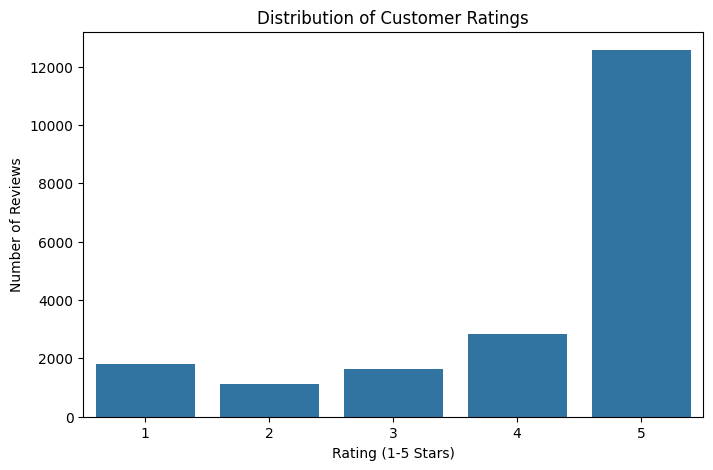

In [ ]:
# Plot the customer rating
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Score')

plt.title('Distribution of Customer Ratings')
plt.xlabel('Rating (1-5 Stars)')
plt.ylabel('Number of Reviews')

plt.show()

In [ ]:
# Average Rating
average_rating = df['Score'].mean()
print("Average Customer Rating:", round(average_rating, 2))

Average Customer Rating: 4.16


In [ ]:
# calculating the rating percentage
rating_pecentages = (
    df['Score'].value_counts(normalize=True).sort_index()*100
)

print(rating_pecentages.round(2))

Score
1     9.12
2     5.60
3     8.24
4    14.18
5    62.86
Name: proportion, dtype: float64


In [ ]:
# To check for duplicate
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [ ]:
# Examining review length

df["Review_Length"] = df['Text'].astype(str).apply(len)

print("Average review length:", round(df['Review_Length'].mean(), 2))

print("Shorte review:", df['Review_Length'].min())

print("Longest review:", df['Review_Length'].max())

Average review length: 429.01
Shorte review: 33
Longest review: 10327


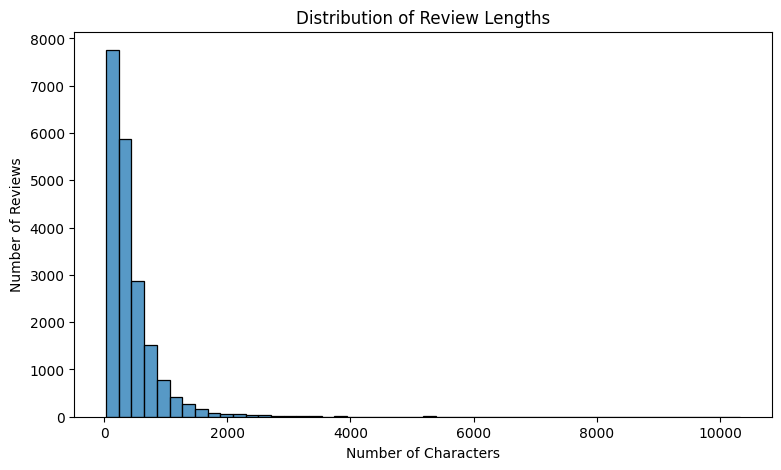

In [ ]:
# Plot the Review
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Review_Length',
    bins=50
)

plt.title('Distribution of Review Lengths')
plt.xlabel('Number of Characters')
plt.ylabel('Number of Reviews')

plt.show()

In [ ]:
# Average review length for each rating
length_by_rating = df.groupby('Score')['Review_Length'].mean()

print(length_by_rating)

Score
1    472.881031
2    476.598214
3    512.355367
4    498.429126
5    391.817437
Name: Review_Length, dtype: float64


Text(0, 0.5, 'Average Character')

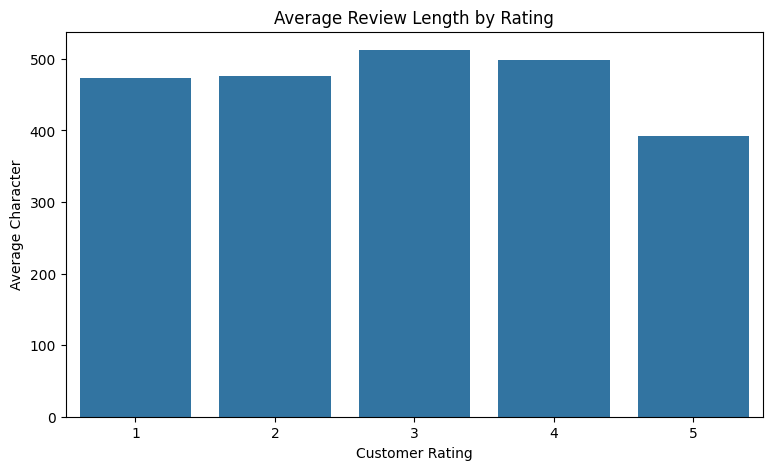

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=length_by_rating.index,
    y=length_by_rating.values
)

plt.title('Average Review Length by Rating')
plt.xlabel('Customer Rating')
plt.ylabel('Average Character')


# Data Cleaning and Preprocessing

In [ ]:
# check for missing values

missing_values = df.isnull().sum()
print(missing_values)

Id                        0
ProductId                 0
UserId                    0
ProfileName               1
HelpfulnessNumerator      0
HelpfulnessDenominator    0
Score                     0
Time                      0
Summary                   0
Text                      0
Review_Length             0
Review_Date               0
Review_Year               0
Review_Month              0
dtype: int64


In [ ]:
# Display the row with missing profileName
df[df['ProfileName'].isnull()]

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,Review_Length,Review_Date,Review_Year,Review_Month
10616,10617,B002DHN956,A1LSYR30XW7CFT,NaN,1,2,5,1291680000,Awesome,This is 72 for the price of like 24 at the gro...,250,2010-12-07 00:00:00+00:00,2010,12


In [ ]:
# Check duplicate records
print("Duplicate rows", df.duplicated().sum())

Duplicate rows 0


In [ ]:
# convert unix timesptamp to datetime
df['Review_Date'] = pd.to_datetime(
  df['Time'],
  unit='s',
  utc=True
)

df[['Time', 'Review_Date']].head()

,Time,Review_Date
0,1303862400,2011-04-27 00:00:00+00:00
1,1346976000,2012-09-07 00:00:00+00:00
2,1219017600,2008-08-18 00:00:00+00:00
3,1307923200,2011-06-13 00:00:00+00:00
4,1350777600,2012-10-21 00:00:00+00:00


In [ ]:
df['Review_Year'] = df['Review_Date'].dt.year
df['Review_Month'] = df['Review_Date'].dt.month
df[['Review_Date', 'Review_Year', 'Review_Month']].head()

,Review_Date,Review_Year,Review_Month
0,2011-04-27 00:00:00+00:00,2011,4
1,2012-09-07 00:00:00+00:00,2012,9
2,2008-08-18 00:00:00+00:00,2008,8
3,2011-06-13 00:00:00+00:00,2011,6
4,2012-10-21 00:00:00+00:00,2012,10


In [ ]:
print("Rating Values")
print(sorted(df['Score'].unique()))

print("\nInvalid ratings")
print(df[~df['Score'].between(1, 5)].shape[0])

Rating Values
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Invalid ratings
0


In [ ]:
# Check data quality
print("Empty review texts:",
      df['Text'].isna().sum())

print("Empty summaries:",
df['Summary'].isna().sum())

print("Empty review strings:", (df['Text'].str.strip() == '').sum())

Empty review texts: 0
Empty summaries: 0
Empty review strings: 0


# Clean and prepate the dataset

In [ ]:
clean_df = df.copy()

# Remove rows with missing text
clean_df = clean_df.dropna(subset=['Text'])

# Remove empty review text
clean_df = clean_df[
    clean_df['Text'].str.strip() != ''
]

# Reset row numbering
clean_df = clean_df.reset_index(drop=True)

print("Orignial rows:", len(df))
print("Cleaned row:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

Orignial rows: 20000
Cleaned row: 20000
Rows removed: 0


Create a sentiment labels

In [ ]:
def assign_sentiment(score):
  if score <= 2:
    return "Negative"
  elif score == 3:
    return "Neutral"
  else:
    return "Positive"


clean_df['Sentiment'] = clean_df['Score'].apply(assign_sentiment)

print(clean_df[['Score', 'Sentiment']].head(10))

   Score Sentiment
0      5  Positive
1      1  Negative
2      4  Positive
3      2  Negative
4      5  Positive
5      4  Positive
6      5  Positive
7      5  Positive
8      5  Positive
9      5  Positive


In [ ]:
print(clean_df['Sentiment'].value_counts())

Sentiment
Positive    15407
Negative     2944
Neutral      1649
Name: count, dtype: int64


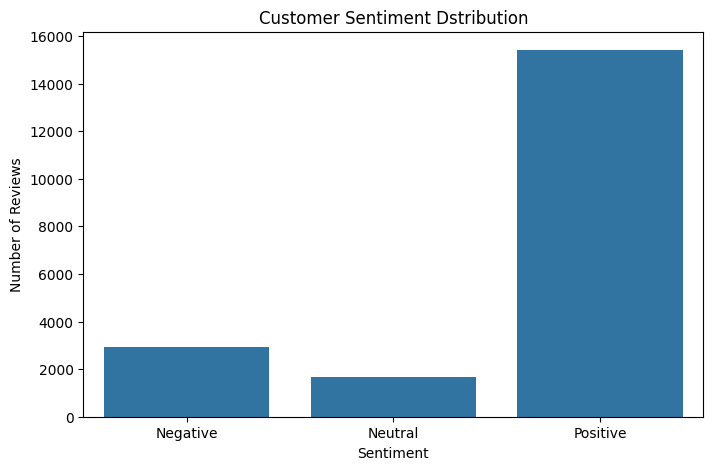

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
  data=clean_df,
  x="Sentiment",
  order=['Negative', 'Neutral', 'Positive']
)

plt.title("Customer Sentiment Dstribution")
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.show()

# Natural Language Processing

In [ ]:
import nltk
import re

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLP libraries successfully initialize")

NLP libraries successfully initialize


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


# Inspecting customer review

In [ ]:
# Inspect the real world customer review
print("ORIGINAL REVIEW:")
print(clean_df['Text'].iloc[1])

print('\nSTAR RATING')
print(clean_df['Score'].iloc[1])

print("\nSENTIMENT")
print(clean_df['Sentiment'].iloc[1])

ORIGINAL REVIEW:
Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as "Jumbo".

STAR RATING
1

SENTIMENT
Negative


In [ ]:
# Build the text cleaning function
stop_words = set(stopwords.words('english'))

negation_words = {'no', 'not', 'nor', 'never'}

lemmatizer = WordNetLemmatizer()

def clean_text(text):

  # convert to lowercase
  text = str(text).lower()

  # Remove HTML tags
  text = re.sub(r'<.*?>', ' ', text)

  # Remove URLs
  text = re.sub(r'http\S+|www\S+', ' ', text)

  # Keep letters and spaces
  text = re.sub(r'[^a-z\s]', ' ', text)

  # Split into individual words
  words = text.split()

# Remove stop words but retain negation words
  words = [
      lemmatizer.lemmatize(word)
      for word in words
      if word not in stop_words or word in negation_words
  ]

  return ' '.join(words)



In [ ]:
# Test the cleaning function

sample_review = clean_df['Text'].iloc[1]

cleaned_review = clean_text(sample_review)

print('\nORIGINAL REVIEW:')
print(sample_review)

print('\nCLEANED REVIEW:')
print(cleaned_review)


ORIGINAL REVIEW:
Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as "Jumbo".

CLEANED REVIEW:
product arrived labeled jumbo salted peanut peanut actually small sized unsalted not sure error vendor intended represent product jumbo


In [ ]:
# Apply the cleaning function to all reviews

clean_df['Cleaned_Text'] = df['Text'].apply(clean_text)

print(
    clean_df[['Text', 'Cleaned_Text', 'Sentiment']].head()
)


                                                Text  \
0  I have bought several of the Vitality canned d...   
1  Product arrived labeled as Jumbo Salted Peanut...   
2  This is a confection that has been around a fe...   
3  If you are looking for the secret ingredient i...   
4  Great taffy at a great price.  There was a wid...   

                                        Cleaned_Text Sentiment  
0  bought several vitality canned dog food produc...  Positive  
1  product arrived labeled jumbo salted peanut pe...  Negative  
2  confection around century light pillowy citrus...  Positive  
3  looking secret ingredient robitussin believe f...  Negative  
4  great taffy great price wide assortment yummy ...  Positive  


# Feature Engineering with FT-TFD

## TF- Termed Frequency: how often a word appears in a particular document
## IDF- Inverse Document Frequency: How rare common that word is across all documents

In [ ]:
# Keep reviews that have cleaned text

ml_df = clean_df[
    clean_df['Cleaned_Text'].notna() &
   (clean_df['Cleaned_Text'].str.strip() != '')
].copy()

# dataset size
print("Number of review: ", len(ml_df))

# check sentiment distribution
print(ml_df['Sentiment'].value_counts())

Number of review:  20000
Sentiment
Positive    15407
Negative     2944
Neutral      1649
Name: count, dtype: int64


In [ ]:
# Import TF-IDF
# TfidVectorizer learn the vocalbulary from our review


from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True
)

print("TF-IDF Vectorizer configured successfully!")

TF-IDF Vectorizer configured successfully!


In [ ]:
X = tfidf.fit_transform(ml_df['Cleaned_Text'])

print("transformation completed")
print("Matrix shape:", X.shape)
print("Number of features", len(tfidf.get_feature_names_out()))

transformation completed
Matrix shape: (20000, 5000)
Number of features 5000


In [ ]:
feature_name = tfidf.get_feature_names_out()

print('First 30 features:')
print(feature_name[:30])


First 30 features:
['ability' 'able' 'able eat' 'able find' 'able get' 'able use' 'absolute'
 'absolute favorite' 'absolutely' 'absolutely delicious' 'absolutely love'
 'absolutely no' 'acai' 'accept' 'acceptable' 'accident' 'according'
 'account' 'accustomed' 'acerola' 'ache' 'acid' 'acidic' 'acidity'
 'acquired' 'acquired taste' 'across' 'act' 'action' 'active']


In [ ]:
# Examine the actual review numerically
review_number = 0

review_vector = X[review_number]

print('Original review:')
print(ml_df['Text'].iloc[review_number])

print('\nCleaned review')
print(ml_df['Cleaned_Text'].iloc[review_number])

print('\nNon-Zero vector')
print(review_vector.nnz)


Original review:
I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than  most.

Cleaned review
bought several vitality canned dog food product found good quality product look like stew processed meat smell better labrador finicky appreciates product better

Non-Zero vector
23


In [ ]:
# View the most important feature in the review

feature_name = tfidf.get_feature_names_out()

scores = review_vector.toarray().flatten()

top_indices = np.argsort(scores)[-1:][::-1]

for index in top_indices:
  if scores[index] > 0:
    print(feature_name[index], round(scores[index], 4))

product found 0.3057


In [ ]:
# Train Test split

from sklearn.model_selection import  train_test_split

# input customer review
X_text = ml_df['Cleaned_Text']

# Target:
y = ml_df['Sentiment']

# split into training and tesing sets

X_train, X_test, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training review:", len(X_train))
print("Testing review:", len(y_test))

Training review: 16000
Testing review: 4000


Build the machine learning pipeline


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

model = Pipeline([
    ('tfidf', TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True
)),

  ('classifier', LogisticRegression(
      max_iter=1000,
      class_weight='balanced',
      random_state=42
  ))

])

print('Machine learninig pipeline created')



Machine learninig pipeline created


In [ ]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


# Save out progress

In [ ]:
import joblib

model_path = project_path + '/sentiment_model.pkl'

joblib.dump(model, model_path)

print("Model saved successfully")
print("Location:", model_path)


Model saved successfully
Location: /content/drive/MyDrive/Customer_Intelligence_Project/sentiment_model.pkl


# Model Evaluation
## Accuracy


In [ ]:
# predict setiment for unseen result
y_pred = model.predict(X_test)

print("Prediction generation successfuly!")
print("Number of prediction:", len(y_pred))

Prediction generation successfuly!
Number of prediction: 4000


In [ ]:
# Claculate the accuracy

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model accuracy:", round(accuracy * 100, 2),'%')

Model accuracy: 80.1 %


## precision

# Confusion Matrix

In [ ]:
from sklearn.metrics import classification_report

print("Classification report:", classification_report(y_test, y_pred))

Classification report:               precision    recall  f1-score   support

    Negative       0.63      0.74      0.68       589
     Neutral       0.30      0.51      0.38       330
    Positive       0.95      0.84      0.89      3081

    accuracy                           0.80      4000
   macro avg       0.63      0.70      0.65      4000
weighted avg       0.85      0.80      0.82      4000



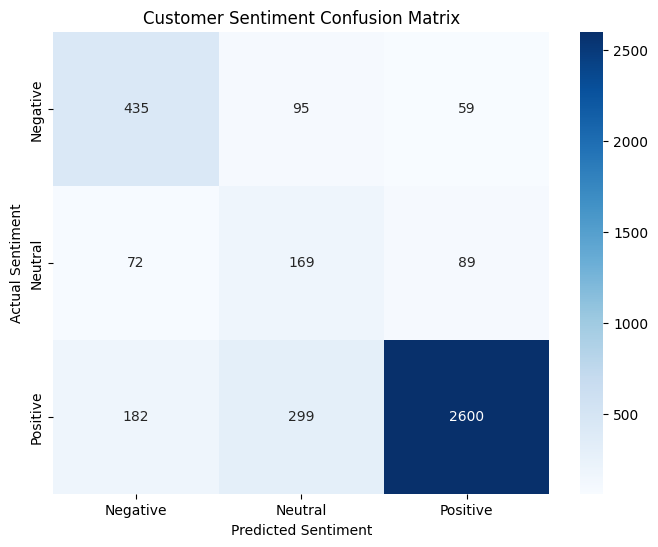

In [ ]:
# Plot the confusion matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Negative', 'Neutral', 'Positive']
)


plt.figure(figsize=(8, 6))

sns.heatmap(
  cm,
  annot=True,
  fmt='d',
  cmap='Blues',
  xticklabels=['Negative', 'Neutral', 'Positive'],
  yticklabels=['Negative', 'Neutral', 'Positive']

)

plt.title("Customer Sentiment Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

In [ ]:
model

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.98, max_features=5000, min_df=2,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [ ]:
classifier = model.named_steps['classifier']

print('Class Weight:', classifier.class_weight)

# the class learned by the model
print('Learned classes:', classifier.classes_)

Class Weight: balanced
Learned classes: ['Negative' 'Neutral' 'Positive']


# EXPERIMENT 2

## Linear SVM



In [ ]:
# import the SVM
from sklearn.svm import LinearSVC
# import the pipleline
from sklearn.pipeline import Pipeline

# Build the model
svm_model = Pipeline([
    ('tfid', model.named_steps['tfidf']),
    ('classifier', LinearSVC(
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model
svm_model.fit(X_train, y_train)
print("Linear SVM training completed!")

Linear SVM training completed!


In [ ]:
# Predict the sentiment using Linear SVM
svm_pred = svm_model.predict(X_test)

print("Prediction completed!")
print("Number of predictions:", len(svm_pred))


Prediction completed!
Number of predictions: 4000


In [ ]:
# Evaluate the model
from sklearn.metrics import accuracy_score, classification_report

svm_accuracy = accuracy_score(y_test, svm_pred)
print('Linear SVM accuracy:',
      round(svm_accuracy * 100, 2), "%")

print('\nClassification report:',
      classification_report(y_test, svm_pred))

Linear SVM accuracy: 83.3 %

Classification report:               precision    recall  f1-score   support

    Negative       0.67      0.69      0.68       589
     Neutral       0.34      0.35      0.35       330
    Positive       0.92      0.91      0.92      3081

    accuracy                           0.83      4000
   macro avg       0.64      0.65      0.65      4000
weighted avg       0.84      0.83      0.83      4000



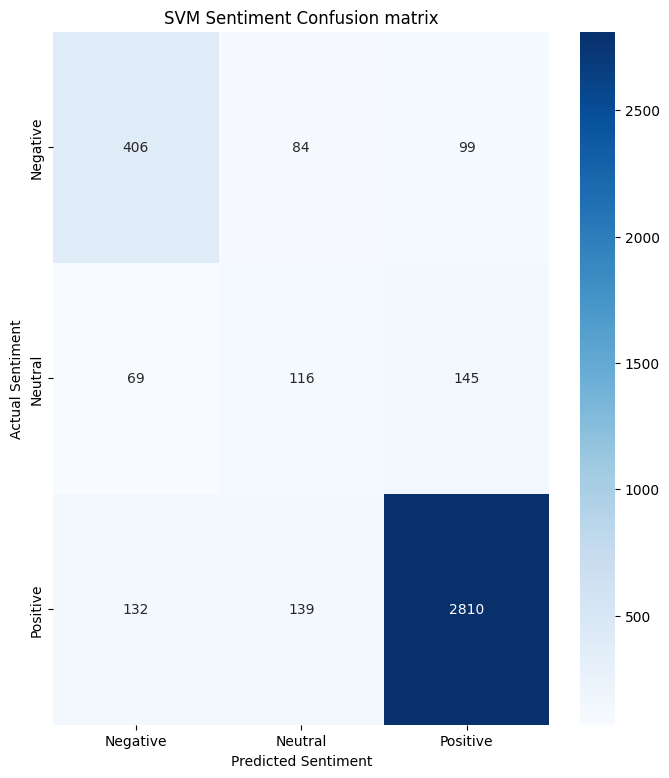

In [ ]:
svm_cm = confusion_matrix(
    y_test,
    svm_pred,
    labels=['Negative', 'Neutral', 'Positive']
)

# Visualize the result
plt.figure(figsize=(8,9))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title('SVM Sentiment Confusion matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

In [ ]:
# Calculate macro F1 for both model

from sklearn.metrics import f1_score

lr_accuracy = accuracy_score(y_test, y_pred)
svm_accuracy =  accuracy_score(y_test, svm_pred)

lr_macro_f1 = f1_score(
    y_test, y_pred, average='macro',
)

svm_macro_f1 = f1_score(
    y_test, svm_pred, average='macro'
)

# Comparison table
comparison = pd.DataFrame({
    'model': ['Logistic Regression', 'Linear SVM'],
    'Accuracy': [lr_accuracy, svm_accuracy],
    'Macro F1': [lr_macro_f1, svm_macro_f1]
})

print(comparison.round(3))

                 model  Accuracy  Macro F1
0  Logistic Regression     0.801     0.650
1           Linear SVM     0.833     0.647


In [ ]:
# Save the comparison to google Drive
comparison.to_csv(
    project_path + '/model_comparison.csv',
    index=False
)

print('Model saved to google drive')

Model saved to google drive


# Test the model

In [ ]:
tet_reviews = [
    "I like the product, reallly good",
    "This is the worst product i ever bought",
    "I kind of like it, don't really know",
    "Good quality, not bad",
    "Well the package arrived late and damaged"
]

# # Generate the prediction
predictions = svm_model.predict(tet_reviews)

# Display predictions
for review, sentiment in zip(tet_reviews, predictions):
  print("Review:", review)
  print("Predicted sentiment:", sentiment)
  print("-" * 60)




Review: I like the product, reallly good
Predicted sentiment: Positive
------------------------------------------------------------
Review: This is the worst product i ever bought
Predicted sentiment: Negative
------------------------------------------------------------
Review: I kind of like it, don't really know
Predicted sentiment: Negative
------------------------------------------------------------
Review: Good quality, not bad
Predicted sentiment: Positive
------------------------------------------------------------
Review: Well the package arrived late and damaged
Predicted sentiment: Positive
------------------------------------------------------------


In [ ]:
from collections import Counter

print("Class learned by the model:")
print(svm_model.classes_)

print("Prediction distribution:")
print(Counter(predictions))

Class learned by the model:
['Negative' 'Neutral' 'Positive']
Prediction distribution:
Counter({'Positive': 3, 'Negative': 2})


In [ ]:
neutral_review = [
    "It arrived later than i expected",
    "This product is average",
    "I kind of like it, don't really know",
    "I have a mix feeling about the package",
    "It is just an ordinary product"

]

neutral_predictions = svm_model.predict(neutral_review)

for review, sentiment in zip(neutral_review, neutral_predictions):
  print("Review:", review)
  print("Prediction:", sentiment)
  print("-" * 60)


Review: It arrived later than i expected
Prediction: Positive
------------------------------------------------------------
Review: This product is average
Prediction: Neutral
------------------------------------------------------------
Review: I kind of like it, don't really know
Prediction: Negative
------------------------------------------------------------
Review: I have a mix feeling about the package
Prediction: Neutral
------------------------------------------------------------
Review: It is just an ordinary product
Prediction: Neutral
------------------------------------------------------------


In [ ]:
# Get decision scores from the SVM
decision_scores = svm_model.decision_function(neutral_review)

for review, scores in zip(neutral_review, decision_scores):

    print("Review:", review)

    for sentiment, score in zip(svm_model.classes_, scores):
        print(sentiment, ":", round(score, 3))

    print("Predicted sentiment:",
          svm_model.predict([review])[0])

    print("-" * 50)

Review: It arrived later than i expected
Negative : -0.991
Neutral : -0.896
Positive : 0.528
Predicted sentiment: Positive
--------------------------------------------------
Review: This product is average
Negative : -0.487
Neutral : 0.639
Positive : -0.68
Predicted sentiment: Neutral
--------------------------------------------------
Review: I kind of like it, don't really know
Negative : 0.388
Neutral : -0.704
Positive : -0.442
Predicted sentiment: Negative
--------------------------------------------------
Review: I have a mix feeling about the package
Negative : -0.22
Neutral : -0.112
Positive : -0.446
Predicted sentiment: Neutral
--------------------------------------------------
Review: It is just an ordinary product
Negative : -0.536
Neutral : 0.848
Positive : -0.557
Predicted sentiment: Neutral
--------------------------------------------------


In [ ]:
# Add vectorizer

vectorizer = svm_model.named_steps['tfid']
classifier = svm_model.named_steps['classifier']

feature_name = vectorizer.get_feature_names_out()

for sentiment, coefficients in zip(
    classifier.classes_,
    classifier.coef_
):
    top_indices = coefficients.argsort()[-15:][::-1]

    print("\nTop words associated with:", sentiment)

    for index in top_indices:
      print(feature_name[index])


Top words associated with: Negative
terrible
worst
disappointed
yuck
died
not
didnt
not recommend
awful
high hope
return
would good
one ounce
wanted like
barely

Top words associated with: Neutral
three star
okay
supposed
ok
least favorite
however
alright
update
not favorite
try brand
half cup
arthritis
unfortunately
certain
otherwise

Top words associated with: Positive
great
delicious
best
not disappointed
excellent
love
hooked
good
favorite
not bitter
wonderful
worried
happy
yummy
pleased


In [ ]:
# get the feature names and trained model coefficients
feature_name = vectorizer.get_feature_names_out()

for sentiment, coefficients in zip(
    classifier.classes_,
    classifier.coef_
):
    top_indices = coefficients.argsort()[-15:][::-1]

    results = pd.DataFrame({
      "word of phrase": feature_name[top_indices],
      "model weight": coefficients[top_indices]
    })

    print("\nSentiment:", sentiment)
    display(results)


Sentiment: Negative


,word of phrase,model weight
0,terrible,3.352733
1,worst,3.257429
2,disappointed,3.224917
3,yuck,3.224229
4,died,3.066476
5,not,2.754405
6,didnt,2.636961
7,not recommend,2.630458
8,awful,2.536472
9,high hope,2.410053



Sentiment: Neutral


,word of phrase,model weight
0,three star,3.605365
1,okay,3.449122
2,supposed,3.266801
3,ok,3.201492
4,least favorite,3.024934
5,however,2.851557
6,alright,2.804725
7,update,2.689962
8,not favorite,2.671003
9,try brand,2.649821



Sentiment: Positive


,word of phrase,model weight
0,great,3.327091
1,delicious,2.856917
2,best,2.691037
3,not disappointed,2.585328
4,excellent,2.458756
5,love,2.335290
6,hooked,2.209649
7,good,2.193429
8,favorite,2.116953
9,not bitter,2.039089


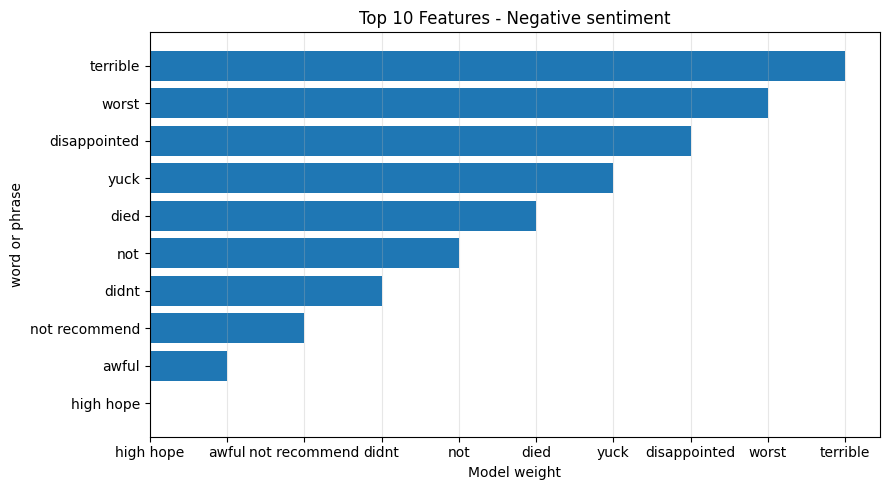

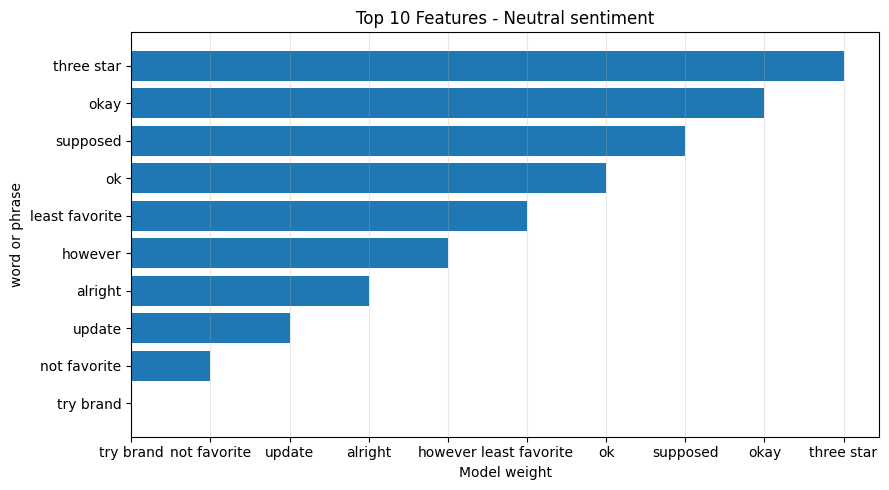

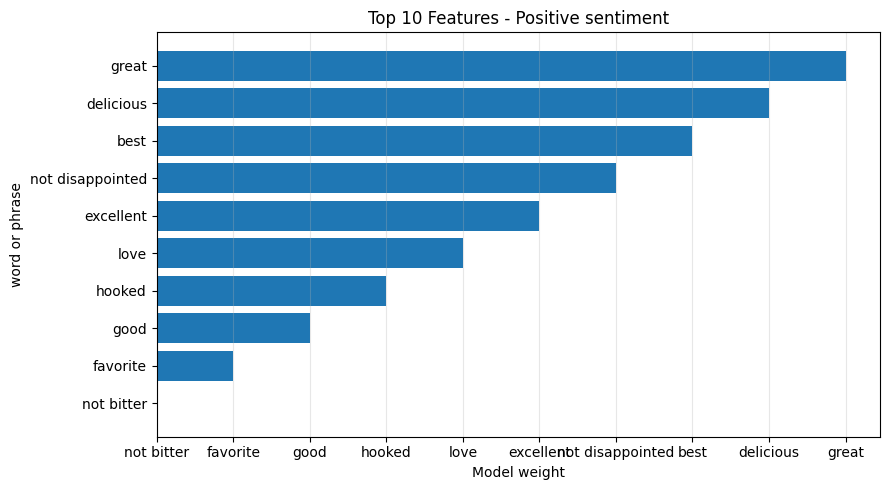

In [ ]:
# Visualize the leanred features
for sentiment, coefficients in zip(
    classifier.classes_,
    classifier.coef_
):
    top_indices = coefficients.argsort()[-10:]

    words = feature_name[top_indices]
    weight = feature_name[top_indices]

    plt.figure(figsize=(9,5))

    plt.barh(words, weight)

    plt.title(f'Top 10 Features - {sentiment} sentiment')
    plt.xlabel('Model weight')
    plt.ylabel('word or phrase')

    plt.xticks(rotation=0)
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

# Improving Model Performance

In [ ]:
# the number of example in each sentiment class

print("Training data distribution:")
print(y_train.value_counts())

print("\nTesting data distribution")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training data distribution:
Sentiment
Positive    12326
Negative     2355
Neutral      1319
Name: count, dtype: int64

Testing data distribution
Sentiment
Positive    77.03
Negative    14.72
Neutral      8.25
Name: proportion, dtype: float64


In [ ]:
print(
    pd.crosstab(
        clean_df["Score"],
        clean_df["Sentiment"]))

Sentiment  Negative  Neutral  Positive
Score                                 
1              1824        0         0
2              1120        0         0
3                 0     1649         0
4                 0        0      2836
5                 0        0     12571


# Experiment 1; Training with Reduced Class Imbalance

In [ ]:
from sklearn.utils import resample
import pandas as pd

# combine training text and labels
train_data = pd.DataFrame({
    "Text": X_train,
    "sentiment": y_train
})


# Combine training text and lebel
train_data = pd.DataFrame({
    "Text": X_train,
    "sentiment": y_train
})

# Separate the three sentiment classes
positive = train_data[
    train_data['sentiment'] == "Positive"
]

negative = train_data[
    train_data['sentiment'] == "Negative"
]

neutral = train_data[
    train_data['sentiment'] == "Neutral"
]

# Reduce the positive cass to 4,000 examples

positive_reduce = resample(
    positive,
    replace=False,
    n_samples=4000,
    random_state=42
)

# Combine all three together
balanced_train = pd.concat([
    positive_reduce,
    negative,
    neutral
])

# Shufffle the training dataset
balanced_train = balanced_train.sample(
    frac=1,
    random_state=42
)

# separate text and labels again
x_train_balanced = balanced_train["Text"]
y_train_balanced = balanced_train["sentiment"]

# Check the distributioin
print(y_train_balanced.value_counts())

sentiment
Positive    4000
Negative    2355
Neutral     1319
Name: count, dtype: int64


# Retrain the Logistic Regression Model

In [ ]:
from sklearn import pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score


# Build the new model
balanced_lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        min_df=2,
        max_df=0.98,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),

    ('classifier', LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=422
    ))
])

# Train using balanced data
balanced_lr_model.fit(
    x_train_balanced,
    y_train_balanced
)


# Predict using the original test data
lr_predictions = balanced_lr_model.predict(X_test)

# Evaluate
print("Balanced Logistic Regression Results")
print("Accuracy:", round(
    accuracy_score(y_test, lr_predictions) * 100, 2
), "%")

print(classification_report(y_test, lr_predictions))

Balanced Logistic Regression Results
Accuracy: 77.38 %
              precision    recall  f1-score   support

    Negative       0.60      0.74      0.66       589
     Neutral       0.27      0.53      0.35       330
    Positive       0.95      0.81      0.87      3081

    accuracy                           0.77      4000
   macro avg       0.61      0.69      0.63      4000
weighted avg       0.84      0.77      0.80      4000



# Balanced Data Without Class Weights

In [ ]:
balanced_lr_no_weight = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        min_df=2,
        max_df=0.98,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),

    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=422
    ))
])

# Train the model
balanced_lr_no_weight.fit(
    x_train_balanced,
    y_train_balanced
)

# Predict using the original test data
lr_no_weights_predictions = balanced_lr_no_weight.predict(X_test)

# Evaluate
print("Balanced Logistic Regression - No class weights")

print(
    classification_report(
        y_test,
        lr_no_weights_predictions
    )
)



Balanced Logistic Regression - No class weights
              precision    recall  f1-score   support

    Negative       0.64      0.76      0.70       589
     Neutral       0.43      0.29      0.35       330
    Positive       0.92      0.92      0.92      3081

    accuracy                           0.84      4000
   macro avg       0.66      0.66      0.66      4000
weighted avg       0.84      0.84      0.84      4000



# Experiment 3: Full dataset with class wreighting

In [ ]:
lr_weighted_full = Pipeline([
    ('tfdf', TfidfVectorizer(
        max_features=5000,
        min_df=2,
        max_df=0.98,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
        ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train using the complete original training data

lr_weighted_full.fit(
    X_train,
    y_train
)

# Predict
lr_weighted_full_predictions = lr_weighted_full.predict(X_test)

# Evaluate
print("Full Dataset with class weights")

print(classification_report(
    y_test,
    lr_weighted_full_predictions
))

Full Dataset with class weights
              precision    recall  f1-score   support

    Negative       0.63      0.74      0.68       589
     Neutral       0.30      0.51      0.38       330
    Positive       0.95      0.84      0.89      3081

    accuracy                           0.80      4000
   macro avg       0.63      0.70      0.65      4000
weighted avg       0.85      0.80      0.82      4000



In [ ]:
import textwrap

# Rebuild error analysis using original review text
error_analysis = pd.DataFrame({
    "Review": clean_df.loc[X_test.index, "Text"],
    "Actual": y_test,
    "Predicted": lr_weighted_full_predictions
}, index=X_test.index)

# Select incorrectly classified neutral reviews
neutral_errors = error_analysis[
    (error_analysis["Actual"] == "Neutral") &
    (error_analysis["Predicted"] != "Neutral")
]

print("Misclassified neutral reviews:", len(neutral_errors))

# Display original reviews
for _, row in neutral_errors.head(10).iterrows():

    print("\nORIGINAL CUSTOMER REVIEW:")
    print(textwrap.fill(str(row["Review"]), width=85))

    print("Actual sentiment:", row["Actual"])
    print("Predicted sentiment:", row["Predicted"])

    print("-" * 85)

Misclassified neutral reviews: 161

ORIGINAL CUSTOMER REVIEW:
I took it at 5am yesterday. It is now almost 3am the next day and I am laying in bed
and skin feels tingly, can't sleep at all. I feel like I am at super sayan level 4,
power of the red monkey. I could shoot ki blast out the window if I wanted too. Maybe
some kame hame wave's too.
Actual sentiment: Neutral
Predicted sentiment: Negative
-------------------------------------------------------------------------------------

ORIGINAL CUSTOMER REVIEW:
Wish I would have read the reviews that discuss the product's performance in hot air
poppers.  The PC is very tasty and light with no residual kernel shells that get
stuck in your teeth...4 stars.<br /><br />Problem with using it in hot air poppers is
that the kernels are too light and fly out of the machine before they pop.  Tilting
the machine helps keep them inside, but it would be simpler just to find another
larger kernel corn.
Actual sentiment: Neutral
Predicted sentiment: Pos

In [ ]:
# Investigate the original star rating
# Examine the original reviews alongside their star ratings

error_analysis = pd.DataFrame({
    "Review": clean_df.loc[X_test.index, "Text"],
    "Score": clean_df.loc[X_test.index, "Score"],
    "Actual": y_test,
    "Predicted": lr_weighted_full_predictions
}, index=X_test.index)

# Select incorrectly classified neutral reviews
neutral_errors = error_analysis[
    (error_analysis["Actual"] == "Neutral") &
    (error_analysis["Predicted"] != "Neutral")
]

# Display the first 10 examples
for _, row in neutral_errors.head(10).iterrows():

    print("\nREVIEW:")
    print(textwrap.fill(str(row["Review"]), width=85))

    print("Star rating:", row["Score"])
    print("Actual label:", row["Actual"])
    print("Predicted label:", row["Predicted"])

    print("-" * 85)


REVIEW:
I took it at 5am yesterday. It is now almost 3am the next day and I am laying in bed
and skin feels tingly, can't sleep at all. I feel like I am at super sayan level 4,
power of the red monkey. I could shoot ki blast out the window if I wanted too. Maybe
some kame hame wave's too.
Star rating: 3
Actual label: Neutral
Predicted label: Negative
-------------------------------------------------------------------------------------

REVIEW:
Wish I would have read the reviews that discuss the product's performance in hot air
poppers.  The PC is very tasty and light with no residual kernel shells that get
stuck in your teeth...4 stars.<br /><br />Problem with using it in hot air poppers is
that the kernels are too light and fly out of the machine before they pop.  Tilting
the machine helps keep them inside, but it would be simpler just to find another
larger kernel corn.
Star rating: 3
Actual label: Neutral
Predicted label: Positive
---------------------------------------------------

# CREATE A CLEANER SENTIMENT LABELS

In [ ]:
# Create a copy of our cleaned dataset
binary_df = clean_df.copy()

# Keep only reviews with clear star ratings
binary_df = binary_df[
    binary_df["Score"].isin([1, 2, 4, 5])
].copy()

# Convert star ratings into sentiment labels
binary_df["Sentiment"] = binary_df["Score"].apply(
    lambda score: "Negative" if score <= 2 else "Positive"
)

# Check the new dataset
print("New dataset size:", len(binary_df))

print("\nSentiment distribution:")
print(binary_df["Sentiment"].value_counts())

print("\nSentiment percentages:")
print(
    binary_df["Sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

New dataset size: 18351

Sentiment distribution:
Sentiment
Positive    15407
Negative     2944
Name: count, dtype: int64

Sentiment percentages:
Sentiment
Positive    83.96
Negative    16.04
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

# Select the review text
text_column = (
    "Cleaned_Text" if "Cleaned_Text" in binary_df.columns
    else "Text"
)

X = binary_df[text_column]
y = binary_df["Sentiment"]

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Combine training text and labels
train_data = pd.DataFrame({
    "Text": X_train,
    "Sentiment": y_train
})

# Separate positive and negative reviews
positive = train_data[
    train_data["Sentiment"] == "Positive"
]

negative = train_data[
    train_data["Sentiment"] == "Negative"
]

# Reduce positive reviews to match negative reviews
positive_reduced = positive.sample(
    n=len(negative),
    random_state=42
)

# Combine the balanced training classes
balanced_train = pd.concat([
    positive_reduced,
    negative
])

# Shuffle the training data
balanced_train = balanced_train.sample(
    frac=1,
    random_state=42
)

# Display the new training distribution
print("Balanced training distribution:")
print(balanced_train["Sentiment"].value_counts())

print("\nOriginal testing distribution:")
print(y_test.value_counts())

Balanced training distribution:
Sentiment
Positive    2355
Negative    2355
Name: count, dtype: int64

Original testing distribution:
Sentiment
Positive    3082
Negative     589
Name: count, dtype: int64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Create the machine-learning pipeline
balanced_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True
    )),

    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train using our balanced training dataset
balanced_model.fit(
    balanced_train["Text"],
    balanced_train["Sentiment"]
)

print("Balanced sentiment model trained successfully!")

Balanced sentiment model trained successfully!


BALANCED MODEL RESULTS
Accuracy: 86.22 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.54      0.89      0.68       589
    Positive       0.98      0.86      0.91      3082

    accuracy                           0.86      3671
   macro avg       0.76      0.87      0.79      3671
weighted avg       0.91      0.86      0.87      3671



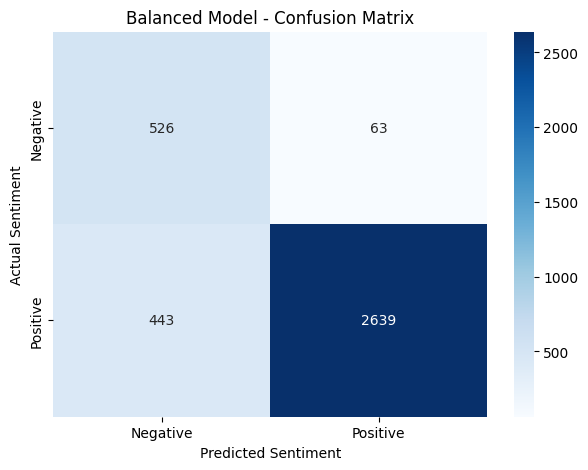

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Predict sentiment on unseen test reviews
binary_predictions = balanced_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, binary_predictions)

print("BALANCED MODEL RESULTS")
print("Accuracy:", round(accuracy * 100, 2), "%")

# Detailed performance report
print("\nClassification Report:")
print(classification_report(
    y_test,
    binary_predictions
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    binary_predictions,
    labels=["Negative", "Positive"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Balanced Model - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

In [ ]:
# Create a dataframe containing predictions
results_df = pd.DataFrame({
    "Review": X_test,
    "Actual": y_test,
    "Predicted": binary_predictions
})

# Find positive reviews predicted as negative
false_negatives = results_df[
    (results_df["Actual"] == "Positive") &
    (results_df["Predicted"] == "Negative")
]

print("Positive reviews incorrectly classified as Negative:")
print("Total:", len(false_negatives))

# Display 10 examples
import textwrap

for _, row in false_negatives.head(10).iterrows():

    print("\nORIGINAL REVIEW:")
    print(textwrap.fill(str(row["Review"]), width=85))

    print("Actual:", row["Actual"])
    print("Predicted:", row["Predicted"])

    print("-" * 85)

Positive reviews incorrectly classified as Negative:
Total: 443

ORIGINAL REVIEW:
expecting much found box big lot actually quite tasty box pretty dented suspect ended
close out store thought turn three picky eater like probably due pizza like flavor
crunchy cracker appeal kid resist
Actual: Positive
Predicted: Negative
-------------------------------------------------------------------------------------

ORIGINAL REVIEW:
well maybe first one review wonderful treat know not first one tried treat safe
healthy yummy native language miam miam yum yum go not sweet yet not lacking
sweetness taste one ingredient one ok besides coconut since mostly made good raw food
product dehydrated low temp really nice give kid love course bit expensive average
treat candy hey want complain want crappy candy dye chemical cooked basically poison
want give real food kid bet people learn prepare treat give kid school would less
filled asperger syndrome add adhd kid etc treat regret spent money unless course 

In [ ]:
# Compare original and cleaned versions of misclassified reviews

comparison = pd.DataFrame({
    "Original Review": clean_df.loc[
        false_negatives.index, "Text"
    ],
    "Cleaned Review": false_negatives["Review"],
    "Actual": false_negatives["Actual"],
    "Predicted": false_negatives["Predicted"]
})

# Display five examples
for _, row in comparison.head(5).iterrows():

    print("\nORIGINAL CUSTOMER REVIEW:")
    print(textwrap.fill(str(row["Original Review"]), width=85))

    print("\nCLEANED REVIEW:")
    print(textwrap.fill(str(row["Cleaned Review"]), width=85))

    print("\nActual:", row["Actual"])
    print("Predicted:", row["Predicted"])

    print("=" * 85)


ORIGINAL CUSTOMER REVIEW:
I wasn't expecting much, having found a box of these for $2 at Big Lots , but they're
actually quite tasty. Most of the boxes were pretty dented, so I suspect that's why
they ended up at the close-outs store). I thought I'd have them all to myself, but it
turns out all three picky eaters like them, too--probably due to the pizza like
flavor with the crunchy cracker appeal that kids can't resist.

CLEANED REVIEW:
expecting much found box big lot actually quite tasty box pretty dented suspect ended
close out store thought turn three picky eater like probably due pizza like flavor
crunchy cracker appeal kid resist

Actual: Positive
Predicted: Negative

ORIGINAL CUSTOMER REVIEW:
Well, maybe I'm the first one to review this wonderful treat, but I know I'm not the
first one having tried them! This treat is so safe, healthy, and yummy! In my native
language, Miam-Miam is for Yum-Yum!<br />There you go. Not too sweet, yet not lacking
sweetness. You can't taste one in

# WE TRANSFER TO DISTILBERT
## Our Logistic Regression and SVM struggle to understand context and review so we switch to DistilBert

In [ ]:
import torch
print("Pytorch version:", torch.__version__)

if torch.cuda.is_available():
  print("GPU Availabele:", torch.cuda.get_device_name(0))

else:
  print("GPU not available, please check your colab runtime settings")

Pytorch version: 2.14.1+cu130
GPU Availabele: Tesla T4


In [ ]:
# Install the transformer libraries
!pip install -q transformers datasets accelerate evaluate

# Create a separate dataset for DistilBERT
bert_df = clean_df.copy()

# Keep the orignial custome  review
bert_df = bert_df.dropna(subset=["Text", "Score"]).copy()

# Convert star ratings into three sentiment classes

def assign_sentiment(score):
  if score <= 2:
    return "Negative"
  elif score == 3:
    return "Neutral"
  else:
    return "Positive"

bert_df["sentiment"] = bert_df["Score"].apply(assign_sentiment)


# Remove empty reviews

bert_df = bert_df[
    bert_df["Text"].astype(str).str.strip() !=""
].copy()

# Display the dataset distribution
print("Total reviews:", len(bert_df))

print("\nSentiment distribution")
print(bert_df["Sentiment"].value_counts())

print("\nSentiment percentages:")
print(
    bert_df["Sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Total reviews: 20000

Sentiment distribution
Sentiment
Positive    15407
Negative     2944
Neutral      1649
Name: count, dtype: int64

Sentiment percentages:
Sentiment
Positive    77.04
Negative    14.72
Neutral      8.24
Name: proportion, dtype: float64


In [ ]:
# Split the dataset

from sklearn.model_selection import train_test_split
# Use our manually labelled dataset
X = sentiment_dataset["Text"]
y = sentiment_dataset["Sentiment"]

# Split: 80% training, 10% validation, 10% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 800
Validation: 100
Testing: 100


## Rebuild the dataframe

In [ ]:
train_df = pd.DataFrame({
    "Text": X_train,
    "Sentiment": y_train
}).reset_index(drop=True)

validation_df = pd.DataFrame({
    "Text": X_val,
    "Sentiment": y_val
}).reset_index(drop=True)

test_df = pd.DataFrame({
    "Text": X_test,
    "Sentiment": y_test
}).reset_index(drop=True)

In [ ]:
train_dataset = ReviewDataset(train_df, tokenizer)
validation_dataset = ReviewDataset(validation_df, tokenizer)
test_dataset = ReviewDataset(test_df, tokenizer)

print("Training:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Testing:", len(test_dataset))

Training: 800
Validation: 100
Testing: 100


## Rebuild DataLoader

In [ ]:
# The dataset Loader
from torch.utils.data import DataLoader

batch_size = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Testing batches:", len(test_loader))


Training batches: 50
Validation batches: 7
Testing batches: 7


## recalculate our class weight

In [ ]:
import numpy as np
import torch
from sklearn.utils.class_weight import compute_class_weight

sentiment_labels = ["Negative", "Neutral", "Positive"]

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array(sentiment_labels),
    y=y_train
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
).to(device)

print("Updated class weights:")
for label, weight in zip(sentiment_labels, class_weights):
    print(label, ":", round(weight.item(), 3))

loss_function = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

Updated class weights:
Negative : 1.905
Neutral : 3.653
Positive : 0.454


## Load a Fresh DistilBERT Model

In [ ]:
from transformers import AutoModelForSequenceClassification

# Load a completely fresh three-class model
model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=3,
    id2label={
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    },
    label2id={
        "Negative": 0,
        "Neutral": 1,
        "Positive": 2
    }
)

# Move model to GPU
model = model.to(device)

print("Fresh DistilBERT model loaded successfully!")
print("Number of classes:", model.config.num_labels)
print("Labels:", model.config.id2label)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fresh DistilBERT model loaded successfully!
Number of classes: 3
Labels: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}


## Load a fresh distillBERT model

In [ ]:
from transformers import AutoModelForSequenceClassification

# Load a completely fresh three-class model
model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=3,
    id2label={
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    },
    label2id={
        "Negative": 0,
        "Neutral": 1,
        "Positive": 2
    }
)

# Move model to GPU
model = model.to(device)

print("Fresh DistilBERT model loaded successfully!")
print("Number of classes:", model.config.num_labels)
print("Labels:", model.config.id2label)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fresh DistilBERT model loaded successfully!
Number of classes: 3
Labels: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}


## Create a new optimizer and loss function

In [ ]:
from torch.optim import AdamW
import torch.nn as nn

# Optimizer
optimizer = AdamW(
    model.parameters(),
    lr=2e-5
)

# Weighted loss function
loss_function = nn.CrossEntropyLoss(
    weight=class_weights
)

# Training settings
epochs = 5

print("Optimizer:", optimizer)
print("Epochs:", epochs)
print("Learning rate:", 2e-5)
print("Weighted loss function configured!")

Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 2e-05
    maximize: False
    weight_decay: 0.01
)
Epochs: 5
Learning rate: 2e-05
Weighted loss function configured!


## Train DistilBERT

In [ ]:
import copy
import torch
from tqdm.auto import tqdm

best_validation_loss = float("inf")
best_model_state = None

for epoch in range(epochs):

    # TRAINING
    model.train()
    total_train_loss = 0

    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1} - Training"):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = loss_function(outputs.logits, labels)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    # VALIDATION
    model.eval()
    total_validation_loss = 0

    with torch.no_grad():

        for batch in tqdm(validation_loader, desc="Validation"):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = loss_function(outputs.logits, labels)

            total_validation_loss += loss.item()

    avg_validation_loss = total_validation_loss / len(validation_loader)

    print(f"\nEpoch {epoch+1}/{epochs}")
    print(f"Training loss: {avg_train_loss:.4f}")
    print(f"Validation loss: {avg_validation_loss:.4f}")

    # SAVE THE BEST MODEL
    if avg_validation_loss < best_validation_loss:

        best_validation_loss = avg_validation_loss
        best_model_state = copy.deepcopy(model.state_dict())

        print("New best model saved!")

# RESTORE BEST MODEL
if best_model_state is not None:
    model.load_state_dict(best_model_state)

print("\nTraining completed!")
print("Best validation loss:", round(best_validation_loss, 4))

Epoch 1 - Training:   0%|          | 0/50 [00:00<?, ?it/s]

Validation:   0%|          | 0/7 [00:00<?, ?it/s]


Epoch 1/5
Training loss: 1.0611
Validation loss: 0.9844
New best model saved!


Epoch 2 - Training:   0%|          | 0/50 [00:00<?, ?it/s]

Validation:   0%|          | 0/7 [00:00<?, ?it/s]


Epoch 2/5
Training loss: 0.6938
Validation loss: 0.6719
New best model saved!


... (5 outputs left out)


Epoch 4/5
Training loss: 0.2170
Validation loss: 1.0362


Epoch 5 - Training:   0%|          | 0/50 [00:00<?, ?it/s]

Validation:   0%|          | 0/7 [00:00<?, ?it/s]


Epoch 5/5
Training loss: 0.1185
Validation loss: 0.8490

Training completed!
Best validation loss: 0.6719


## Evaluate the model


DISTILBERT - MANUALLY LABELLED TEST RESULTS

              precision    recall  f1-score   support

    Negative       0.86      0.67      0.75        18
     Neutral       0.43      0.33      0.38         9
    Positive       0.89      0.96      0.92        73

    accuracy                           0.85       100
   macro avg       0.72      0.65      0.68       100
weighted avg       0.84      0.85      0.84       100



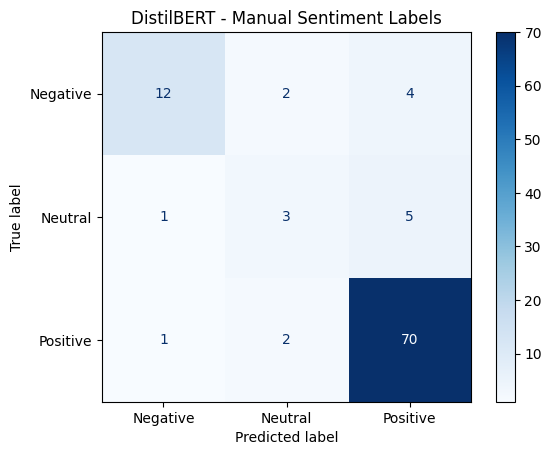

In [ ]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

model.eval()

all_predictions = []
all_actual = []

with torch.no_grad():

    for batch in test_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        all_predictions.extend(predictions.cpu().numpy())
        all_actual.extend(labels.cpu().numpy())


# Classification report
print("DISTILBERT - MANUALLY LABELLED TEST RESULTS\n")

print(classification_report(
    all_actual,
    all_predictions,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))


# Confusion matrix
cm = confusion_matrix(
    all_actual,
    all_predictions,
    labels=[0, 1, 2]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("DistilBERT - Manual Sentiment Labels")
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


import os

progress_file = "/content/drive/MyDrive/sentiment_labelling_progress.xlsx"

def save_progress():
    sample_reviews.to_excel(progress_file, index=False)

def label_review(sentiment):
    global current_index

    sample_reviews.loc[current_index, "Manual_Sentiment"] = sentiment

    save_progress()

    if current_index < len(sample_reviews) - 1:
        current_index += 1

    show_review()